# 📊 StudentScope: Student Lifestyle & Performance Explorer

### Data Science | Week 1 — Exploratory Data Analysis (EDA)

**Dataset:** UCI Student Performance (Portuguese language course)  
**Tools:** Python, Pandas, Matplotlib, Seaborn  
**Level:** Beginner

---

## 1. Project Introduction

StudentScope explores a public student-performance dataset to understand how student background, study habits, and access to resources relate to academic results.

This notebook focuses on the everyday pandas workflow: loading a CSV, inspecting rows and columns, summarising categorical answers, checking missing values, grouping numeric values, and creating clear charts.

> This is an exploratory project. Group differences show associations in this dataset; they do not prove that one factor causes academic performance.

## 2. Project Objectives

1. Load a public dataset into pandas.
2. Inspect its dimensions, columns, data types, and summary statistics.
3. Explore at least four categorical variables.
4. identify missing values.
5. Compare a numeric measure across categories using `groupby`.
6. Create readable visualisations.
7. Summarise findings using values calculated by the notebook.

## 3. Dataset Description

The UCI Student Performance dataset contains student attributes and school-related information. This notebook uses the Portuguese-language course file (`student-por.csv`). The file is separated by semicolons, so `sep=';'` is specified when reading it.

**Source:** [UCI Machine Learning Repository — Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance)

### Main fields used

- `school`, `sex`, `address`, `famsize`: categorical student attributes
- `studytime`: weekly study-time category
- `internet`: home internet access indicator
- `absences`: number of school absences
- `G1`, `G2`, `G3`: period 1, period 2, and final grades

Grades are on a 0–20 scale in the source dataset.

## 4. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("StudentScope EDA started!")

StudentScope EDA started!


## 5. Load the Public Dataset

Download `student-por.csv` from the UCI dataset page, then upload it when the next code cell prompts you. The upload code automatically uses the actual filename, even if Google Colab renames a duplicate upload.

The CSV uses semicolons as separators, so we specify `sep=';'` when reading it.

In [2]:
from google.colab import files

uploaded = files.upload()

# Use the actual uploaded filename (Colab may rename duplicate uploads).
csv_file = next(iter(uploaded))
df = pd.read_csv(csv_file, sep=';')
original_column_count = df.shape[1]

print("Dataset loaded successfully!")
print("Uploaded file:", csv_file)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Saving student-por.csv to student-por.csv
Dataset loaded successfully!
Uploaded file: student-por.csv
Rows: 649
Columns: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


## 6. Explore the Dataset Structure

Use `.info()` to inspect data types and non-null counts, and `.describe()` to review numeric summaries.

In [3]:
print("========== DATASET INFORMATION ==========")
df.info()

print("\n========== NUMERIC SUMMARY ==========")
display(df.describe())

print("\n========== COLUMNS ==========")
print(df.columns.tolist())

print("\nDataset shape:", df.shape)

========== DATASET INFORMATION ==========
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      649 non-null    object
 1   sex         649 non-null    object
 2   age         649 non-null    int64 
 3   address     649 non-null    object
 4   famsize     649 non-null    object
 5   Pstatus     649 non-null    object
 6   Medu        649 non-null    int64 
 7   Fedu        649 non-null    int64 
 8   Mjob        649 non-null    object
 9   Fjob        649 non-null    object
 10  reason      649 non-null    object
 11  guardian    649 non-null    object
 12  traveltime  649 non-null    int64 
 13  studytime   649 non-null    int64 
 14  failures    649 non-null    int64 
 15  schoolsup   649 non-null    object
 16  famsup      649 non-null    object
 17  paid        649 non-null    object
 18  activities  649 non-null    object
 19  nursery 

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000,649.000000
mean,16.744222,2.514638,2.306626,1.568567,1.930663,0.221880,3.930663,3.180277,3.184900,1.502311,2.280431,3.536210,3.659476,11.399076,11.570108,11.906009
std,1.218138,1.134552,1.099931,0.748660,0.829510,0.593235,0.955717,1.051093,1.175766,0.924834,1.284380,1.446259,4.640759,2.745265,2.913639,3.230656
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,16.000000,2.000000,1.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,2.000000,0.000000,10.000000,10.000000,10.000000
50%,17.000000,2.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,2.000000,11.000000,11.000000,12.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,6.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,32.000000,19.000000,19.000000,19.000000



========== COLUMNS ==========
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Dataset shape: (649, 33)


## 7. Explore Four or More Categorical Variables

Review the most common responses and their percentages. The percentage calculation excludes missing values for each column.

In [4]:
categorical_columns = ["school", "sex", "address", "internet", "famsize"]

for column in categorical_columns:
    print(f"\n========== {column.upper()} ==========")
    counts = df[column].value_counts(dropna=False)
    percentages = df[column].value_counts(normalize=True, dropna=False).mul(100).round(2)

    display(pd.DataFrame({
        "count": counts,
        "percentage": percentages
    }))


========== SCHOOL ==========


,count,percentage
school,,
GP,423,65.18
MS,226,34.82



========== SEX ==========


,count,percentage
sex,,
F,383,59.01
M,266,40.99



========== ADDRESS ==========


,count,percentage
address,,
U,452,69.65
R,197,30.35



========== INTERNET ==========


,count,percentage
internet,,
yes,498,76.73
no,151,23.27



========== FAMSIZE ==========


,count,percentage
famsize,,
GT3,457,70.42
LE3,192,29.58


## 8. Identify Missing Values

This step identifies missing data; it does not remove or fill any values.

In [5]:
missing_counts = df.isnull().sum()
missing_percent = (missing_counts / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percent": missing_percent
}).sort_values("missing_count", ascending=False)

display(missing_summary)

print("Columns containing missing values:")
display(missing_summary[missing_summary["missing_count"] > 0])

,missing_count,missing_percent
school,0,0.0
sex,0,0.0
age,0,0.0
address,0,0.0
famsize,0,0.0
Pstatus,0,0.0
Medu,0,0.0
Fedu,0,0.0
Mjob,0,0.0
Fjob,0,0.0


Columns containing missing values:


,missing_count,missing_percent


## 9. Grouped Analysis — Final Grade by Study Time

`studytime` is an ordered category in the dataset (from lower to higher weekly study time). Compare the mean final grade (`G3`) and the number of students in each group. This is descriptive, not causal.

In [6]:
grade_by_studytime = (
    df.groupby("studytime")["G3"]
      .agg(["count", "mean", "median"])
      .sort_index()
)

display(grade_by_studytime.round(2))

,count,mean,median
studytime,,,
1,212,10.84,11.0
2,305,12.09,12.0
3,97,13.23,13.0
4,35,13.06,13.0


## 10. Visualisation 1 — Student Count by School

A bar chart of the number of records from each school.

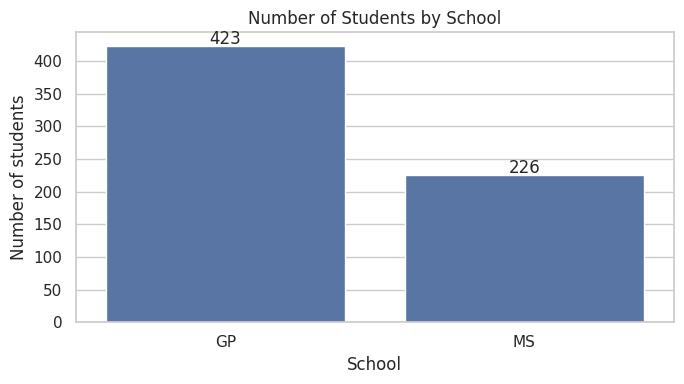

In [7]:
school_counts = df["school"].value_counts()

plt.figure(figsize=(7, 4))
ax = sns.barplot(x=school_counts.index, y=school_counts.values)
ax.set_title("Number of Students by School")
ax.set_xlabel("School")
ax.set_ylabel("Number of students")

for i, value in enumerate(school_counts.values):
    ax.text(i, value + 3, f"{value:,}", ha="center")

plt.tight_layout()
plt.show()

## 11. Visualisation 2 — Final Grade by Study Time

The box plot shows the distribution of final grades within each study-time category. It helps compare medians and spread, not just averages.

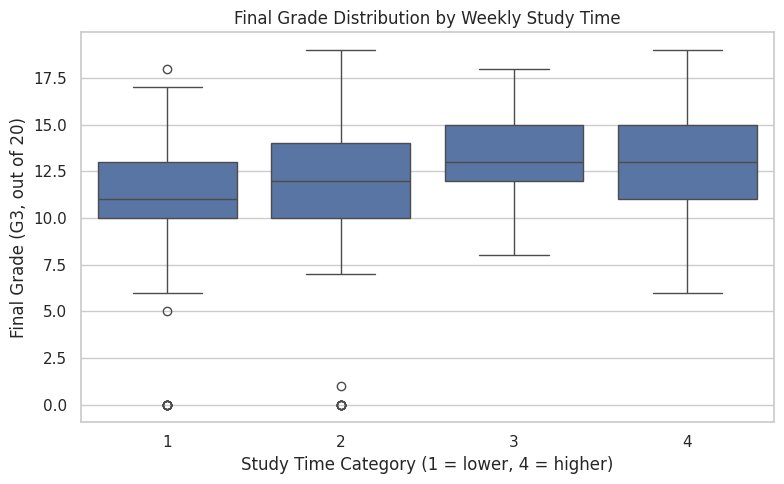

In [8]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="studytime", y="G3")
plt.title("Final Grade Distribution by Weekly Study Time")
plt.xlabel("Study Time Category (1 = lower, 4 = higher)")
plt.ylabel("Final Grade (G3, out of 20)")
plt.tight_layout()
plt.show()

## 12. Visualisation 3 — Distribution of Final Grades

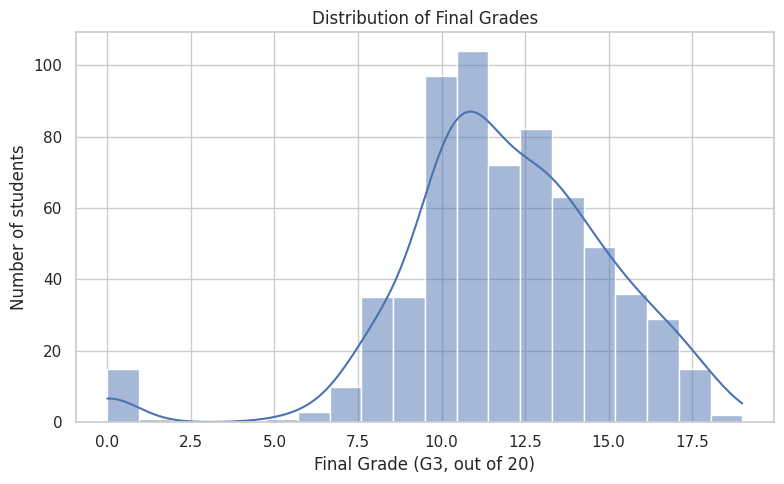

In [12]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="G3", bins=20, kde=True)
plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (G3, out of 20)")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

## 13. Optional Stretch Goal — Crosstab and Heatmap

Compare home internet access with the final-grade band. The grade bands below are created for this analysis only: below 10 and 10 or above. Row-normalised percentages make groups of different sizes easier to compare.

grade_band,10 or above,Below 10
internet,,
no,78.8,21.2
yes,86.3,13.7


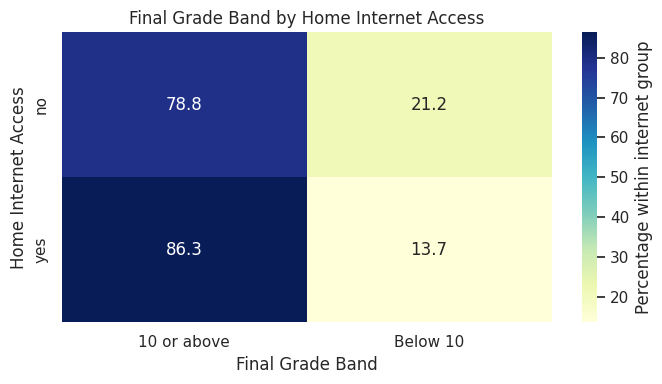

In [10]:
df["grade_band"] = np.where(df["G3"] >= 10, "10 or above", "Below 10")

internet_grade = pd.crosstab(
    df["internet"],
    df["grade_band"],
    normalize="index"
).mul(100)

display(internet_grade.round(1))

plt.figure(figsize=(7, 4))
sns.heatmap(
    internet_grade,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    cbar_kws={"label": "Percentage within internet group"}
)
plt.title("Final Grade Band by Home Internet Access")
plt.xlabel("Final Grade Band")
plt.ylabel("Home Internet Access")
plt.tight_layout()
plt.show()

## 14. Key Findings (Calculated from This Dataset)

The following cell generates actual values from the loaded data. Use its output to write your own short interpretation.

In [11]:
# Calculate findings directly from the dataset
print(f"1. The dataset contains {len(df):,} student records and {original_column_count} original columns.")

largest_school = df["school"].value_counts().idxmax()
largest_school_n = int(df["school"].value_counts().max())
print(f"2. The school with the most records is {largest_school} ({largest_school_n:,} students).")

most_common_sex = df["sex"].value_counts().idxmax()
sex_n = int(df["sex"].value_counts().max())
print(f"3. The most common recorded sex category is {most_common_sex} ({sex_n:,} students).")

mean_grade = df["G3"].mean()
print(f"4. The overall mean final grade (G3) is {mean_grade:.2f} out of 20.")

best_study_group = grade_by_studytime["mean"].idxmax()
best_study_mean = grade_by_studytime.loc[best_study_group, "mean"]
print(f"5. The highest mean G3 among study-time groups is category {best_study_group} ({best_study_mean:.2f}).")

total_missing = int(df.isnull().sum().sum())
print(f"6. Total missing cells in the original dataset: {total_missing:,}.")

1. The dataset contains 649 student records and 33 original columns.
2. The school with the most records is GP (423 students).
3. The most common recorded sex category is F (383 students).
4. The overall mean final grade (G3) is 11.91 out of 20.
5. The highest mean G3 among study-time groups is category 3 (13.23).
6. Total missing cells in the original dataset: 0.


## 15. Conclusion and Limitations

In this project, we loaded the UCI Student Performance dataset and practised the core pandas EDA workflow. We inspected the dataset, explored categorical variables, checked missing values, compared final grades across study-time groups, and created visualisations.

**Limitations:**
- The dataset represents students from two Portuguese schools; it should not be treated as representative of all students.
- Group averages and charts describe associations and do not establish cause and effect.
- The study-time variable is categorical, so its values represent bands rather than exact hours.
- The analysis does not predict an individual student's future grade.

**Next step:** A later data-cleaning task could examine data quality, prepare features, and investigate relationships more carefully.

**Dataset source:** [UCI Machine Learning Repository — Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance).